# Residual MLP Fingerprint Predictor

Predicts a molecular fingerprint from a binned spectrum using a residual multilayer perceptron, then ranks mass-matched candidates by similarity to the prediction. Because candidates are scored from structure alone, this approach can rank molecules with no reference spectrum.

### Configuration
Defines file locations, model size and training parameters. `DRIVE_DATA_DIR` is the Google Drive folder holding the competition data, and `DRIVE_RUN_ROOT` is where run outputs are stored. `QUICK_RUN` limits the run to a small sample for verifying the pipeline; keep it `False` for reported results. `PER_STRUCTURE` caps training spectra per structure, `MAX_MINUTES` sets the training time budget, and `DEVICE_PREFERENCE` selects the accelerator. `SEED` makes model initialization and batch order repeatable.

In [1]:
import os

DRIVE_DATA_DIR = "/content/drive/MyDrive/CASMI/enveda-CASMI26-molecule-id-mass-spectra"
DRIVE_RUN_ROOT = "/content/drive/MyDrive/CASMI/experiment_runs"
QUICK_RUN = False

MODEL_NAME = "residual_mlp"
MODEL_KWARGS = {"n_bins": 1200, "width": 2048, "depth": 4, "dropout": 0.2}
MAX_PEAKS = 128
EPOCHS = 15
BATCH = 1024
LR = 0.0005
PER_STRUCTURE = 8
MAX_MINUTES = 150
VAL_MOLECULES = 3000
PPM = 10
SEED = 42
DEVICE_PREFERENCE = "auto"  # "auto", "cuda", "tpu" or "cpu"

### Dependencies
Installs RDKit on Google Colab at the version used by the competition's scorer. RDKit is needed only to compute fingerprints during training.

In [2]:
import subprocess
import sys

if os.path.exists("/content") and not os.environ.get("KAGGLE_KERNEL_RUN_TYPE"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rdkit==2026.3.3"], check=True)

### Pipeline module
Writes the shared pipeline to `casmi_pipeline.py` in the runtime and keeps the notebook self-contained. The module covers data loading, validation splitting, candidate retrieval, scoring, submission writing, run logging and figures. It also defines the model architectures and training loop.

In [3]:
%%writefile casmi_pipeline.py
"""Retrieval and ranking pipeline for molecule identification from MS/MS spectra.

Provides data loading, validation splitting, candidate retrieval, spectral library
search, neural fingerprint predictors, MRR@25 evaluation, submission writing, run
logging and figures for the Enveda CASMI 2026 competition.
"""

import glob
import hashlib
import os
import re
import sys
import time

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

PROTON = 1.00727646688
ELECTRON = 0.00054857990907
TOP_K = 25
MAX_PPM_LABEL_ERROR = 20.0  # library spectra with a larger precursor error are treated as bad labels

# adduct -> (molecules per ion, absolute charge, mass added to the n*M term)
ADDUCTS = {
    "[M+H]+": (1, 1, PROTON),
    "[M-H]-": (1, 1, -PROTON),
    "[M+Na]+": (1, 1, 22.98976928 - ELECTRON),
    "[M+K]+": (1, 1, 38.96370649 - ELECTRON),
    "[M+NH4]+": (1, 1, 18.03437413 - ELECTRON),
    "[M+Cl]-": (1, 1, 34.96885268 + ELECTRON),
    "[M+CH2O2-H]-": (1, 1, 46.00547930 - PROTON),
    "[M+C2H4O2-H]-": (1, 1, 60.02112937 - PROTON),
    "[M-H2O+H]+": (1, 1, PROTON - 18.01056468),
    "[M-2H2O+H]+": (1, 1, PROTON - 36.02112937),
    "[M]+": (1, 1, -ELECTRON),
    "[M]-": (1, 1, ELECTRON),
    "[M+2H]2+": (1, 2, 2 * PROTON),
    "[2M+H]+": (2, 1, PROTON),
    "[2M+Na]+": (2, 1, 22.98976928 - ELECTRON),
    "[2M-H]-": (2, 1, -PROTON),
}
QUERY_ADDUCTS = ["[M+H]+", "[M-H]-", "[M+Na]+", "[M+NH4]+", "[M+K]+", "[M+Cl]-", "[M+CH2O2-H]-"]
ADDUCT_INDEX = {a: i + 1 for i, a in enumerate(ADDUCTS)}  # 0 means "other"
N_ADDUCTS = len(ADDUCTS) + 1

MONO = {
    "H": 1.00782503207,
    "B": 11.0093054,
    "C": 12.0,
    "N": 14.0030740048,
    "O": 15.99491461956,
    "F": 18.99840322,
    "Na": 22.9897692809,
    "Mg": 23.9850417,
    "Al": 26.98153863,
    "Si": 27.9769265325,
    "P": 30.97376163,
    "S": 31.972071,
    "Cl": 34.96885268,
    "K": 38.96370668,
    "Ca": 39.96259098,
    "Fe": 55.9349375,
    "Co": 58.933195,
    "Ni": 57.9353429,
    "Cu": 62.9295975,
    "Zn": 63.9291422,
    "As": 74.9215965,
    "Se": 79.9165213,
    "Br": 78.9183371,
    "Sn": 119.9021947,
    "I": 126.904473,
    "Pt": 194.9647911,
    "Hg": 201.970643,
}


def find_data_dir(explicit=None):
    """Return the folder holding train.parquet on Kaggle, Colab or a local machine."""
    if explicit and os.path.exists(os.path.join(explicit, "train.parquet")):
        return explicit
    for root in [
        "/kaggle/input/**",
        "/content/casmi_data",
        "../enveda-CASMI26-molecule-id-mass-spectra",
        "../../enveda-CASMI26-molecule-id-mass-spectra",
        ".",
    ]:
        hits = glob.glob(os.path.join(root, "train.parquet"), recursive=True)
        if hits:
            return os.path.dirname(hits[0])
    raise FileNotFoundError("train.parquet not found. Check that the competition data is available to this runtime.")


def formula_mass(formula):
    total = 0.0
    for element, count in re.findall(r"([A-Z][a-z]?)(\d*)", str(formula)):
        if element not in MONO:
            return np.nan
        total += MONO[element] * (int(count) if count else 1)
    return total if total > 0 else np.nan


def neutral_mass(precursor_mz, adduct, mode=None):
    """Neutral monoisotopic mass of one spectrum. Unknown adducts fall back to +/- one proton."""
    if adduct in ADDUCTS:
        n, z, delta = ADDUCTS[adduct]
    else:
        n, z, delta = 1, 1, (-PROTON if str(mode).startswith("neg") else PROTON)
    return (precursor_mz * z - delta) / n


def add_neutral_mass(df):
    df = df.copy()
    df["neutral_mass"] = [
        neutral_mass(m, a, p) for m, a, p in zip(df.precursor_mz, df.adduct, df.ionization_mode, strict=False)
    ]
    return df


def load_meta(data_dir):
    """Load everything in train.parquet except the peak lists."""
    cols = [
        "ingest_lib",
        "inchikey14",
        "normalized_smiles",
        "molecular_formula",
        "ionization_mode",
        "instrument_type",
        "adduct",
        "precursor_mz",
        "precursor_error_ppm",
        "num_peaks",
    ]
    meta = pd.read_parquet(os.path.join(data_dir, "train.parquet"), columns=cols)
    meta["row_id"] = np.arange(len(meta))
    for col in ["ingest_lib", "ionization_mode", "instrument_type", "adduct"]:
        meta[col] = meta[col].astype("category")
    meta["good_label"] = meta.precursor_error_ppm.abs() <= MAX_PPM_LABEL_ERROR
    return meta


def _unit(key, salt):
    digest = hashlib.md5(f"{salt}:{key}".encode()).hexdigest()
    return int(digest[:12], 16) / float(16**12)


def make_split(meta, frac=0.10, salt="casmi-split-v1", max_query_spectra=6):
    """Structure-level validation split that simulates test classes 1 and 2.

    Class 1: the structure keeps reference spectra, but only from other libraries.
    The whole library the query comes from is removed for that structure, because
    the real test spectra are unpublished.
    Class 2: every spectrum of the structure is removed. The structure stays in the
    candidate pool with no reference spectra.

    Returns (queries, library_mask). Queries has one row per query spectrum.
    """
    keys = meta.inchikey14.unique()
    np_keys = set(meta.loc[meta.ingest_lib == "enveda-np-examples", "inchikey14"].unique())
    held = {k for k in keys if _unit(k, salt) < frac or k in np_keys}
    sub = meta[meta.inchikey14.isin(held)]
    excluded = np.zeros(len(meta), dtype=bool)
    rows = []
    rng = np.random.default_rng(20261110)
    for key, group in sub.groupby("inchikey14", sort=True, observed=True):
        eligible = group[group.good_label & group.adduct.isin(QUERY_ADDUCTS) & (group.num_peaks >= 4)]
        if eligible.empty:
            excluded[group.row_id.to_numpy()] = True
            continue
        libs = eligible.ingest_lib.astype(str)
        counts = libs.value_counts()
        if "enveda-np-examples" in counts.index:
            query_lib = "enveda-np-examples"
        elif "enveda-180" in counts.index:
            query_lib = "enveda-180"
        else:
            query_lib = counts.index[0]
        others = group[(group.ingest_lib.astype(str) != query_lib) & group.good_label]
        cls = 1 if (_unit(key, salt + "-class") < 0.5 and len(others) > 0) else 2
        if cls == 1:
            excluded[group.loc[group.ingest_lib.astype(str) == query_lib, "row_id"].to_numpy()] = True
        else:
            excluded[group.row_id.to_numpy()] = True
        pool_rows = eligible[libs == query_lib]
        n = int(min(len(pool_rows), rng.integers(1, max_query_spectra + 1)))
        picked = rng.choice(pool_rows.row_id.to_numpy(), size=n, replace=False)
        for row_id in picked:
            rows.append((int(row_id), f"val_{key}", key, cls, query_lib))
    queries = pd.DataFrame(rows, columns=["row_id", "molecule_id", "true_key", "cls", "query_lib"])
    info = meta.iloc[queries.row_id.to_numpy()]
    for col in ["precursor_mz", "adduct", "ionization_mode"]:
        queries[col] = info[col].astype(object if col != "precursor_mz" else float).to_numpy()
    queries = add_neutral_mass(queries)
    return queries, ~excluded


def sample_molecules(queries, n, seed=7):
    """Keep the enveda-np-examples proxy set, then sample the rest evenly across classes 1 and 2."""
    per_mol = queries.drop_duplicates("molecule_id")
    is_proxy = per_mol.query_lib == "enveda-np-examples"
    keep = set(per_mol[is_proxy].molecule_id)
    rest = per_mol[~is_proxy]
    per_class = max((n - len(keep)) // 2, 0)
    for cls in (1, 2):
        part = rest[rest.cls == cls].molecule_id
        keep |= set(part.sample(min(len(part), per_class), random_state=seed))
    return queries[queries.molecule_id.isin(keep)].reset_index(drop=True)


def build_pool(meta, library_mask, extra_candidates=None):
    """One row per structure, sorted by mass. n_ref counts usable library spectra."""
    pool = meta.drop_duplicates("inchikey14")[["inchikey14", "normalized_smiles", "molecular_formula"]].copy()
    pool.columns = ["key", "smiles", "formula"]
    masses = {f: formula_mass(f) for f in pool.formula.unique()}
    pool["mass"] = pool.formula.map(masses)
    counts = meta.loc[library_mask & meta.good_label.to_numpy(), "inchikey14"].value_counts()
    pool["n_ref"] = pool.key.map(counts).fillna(0).astype(int)
    if extra_candidates is not None:  # optional external candidates with columns: key, smiles, mass
        extra = extra_candidates[~extra_candidates.key.isin(set(pool.key))].copy()
        extra["formula"], extra["n_ref"] = "", 0
        pool = pd.concat([pool, extra[pool.columns]], ignore_index=True)
    pool = pool.dropna(subset=["mass", "smiles"])
    return pool.sort_values(["mass", "key"], kind="stable").reset_index(drop=True)


def consensus_masses(spectra):
    """Median neutral mass per molecule across its spectra and adducts."""
    return spectra.groupby("molecule_id", sort=False).neutral_mass.median()


def window_indices(pool_mass, mass, ppm):
    tol = mass * ppm * 1e-6
    return np.arange(np.searchsorted(pool_mass, mass - tol), np.searchsorted(pool_mass, mass + tol, side="right"))


def nearest_indices(pool_mass, mass, n):
    """The n pool entries closest in mass. Used to fill short lists."""
    center = int(np.searchsorted(pool_mass, mass))
    lo, hi = max(center - n, 0), min(center + n, len(pool_mass))
    idx = np.arange(lo, hi)
    return idx[np.argsort(np.abs(pool_mass[idx] - mass), kind="stable")[:n]]


def fill_to_k(ranked, pool_mass, mass, k=TOP_K):
    """Append nearest-mass structures so the list has k unique entries."""
    ranked = list(dict.fromkeys(int(i) for i in ranked))[:k]
    if len(ranked) < k:
        seen = set(ranked)
        for i in nearest_indices(pool_mass, mass, 4 * k):
            if int(i) not in seen:
                ranked.append(int(i))
                seen.add(int(i))
            if len(ranked) == k:
                break
    return ranked


def rank_b1(pool, mass, ppm=10.0, order="ppm_then_prior"):
    """B1: rank by mass alone. Isomers tie on mass, so reference count breaks ties."""
    pool_mass = pool.mass.to_numpy()
    idx = window_indices(pool_mass, mass, ppm)
    if len(idx):
        err = np.round(np.abs(pool_mass[idx] - mass) / mass * 1e6, 3)
        n_ref = pool.n_ref.to_numpy()[idx]
        primary = (err, -n_ref) if order == "ppm_then_prior" else (-n_ref, err)
        idx = idx[np.lexsort((idx,) + primary[::-1])]
    return fill_to_k(idx, pool_mass, mass)


def rank_table(rankings, truth, pool_keys):
    """One row per molecule with the rank of its true structure (0 means missed)."""
    records = []
    for row in truth.itertuples():
        keys = [pool_keys[i] for i in rankings[row.molecule_id][:TOP_K]]
        rank = keys.index(row.true_key) + 1 if row.true_key in keys else 0
        records.append(
            (row.molecule_id, row.cls, row.query_lib == "enveda-np-examples", 1.0 / rank if rank else 0.0, rank)
        )
    return pd.DataFrame(records, columns=["molecule_id", "cls", "np_proxy", "rr", "rank"])


def evaluate(rankings, truth, pool_keys, ci=False):
    """Per-class MRR@25 and hit rates. 'balanced' averages classes 1 and 2, since the real mix is hidden."""
    res = rank_table(rankings, truth, pool_keys)
    rng = np.random.default_rng(3)

    def summarize(part):
        out = {
            "n": len(part),
            "MRR@25": round(part.rr.mean(), 4),
            "top1": round((part["rank"] == 1).mean(), 4),
            "top5": round(part["rank"].between(1, 5).mean(), 4),
            "top25": round((part["rank"] > 0).mean(), 4),
        }
        if ci and len(part):
            draws = rng.choice(part.rr.to_numpy(), size=(1000, len(part))).mean(axis=1)
            out["MRR_ci_low"], out["MRR_ci_high"] = (
                round(np.quantile(draws, 0.025), 4),
                round(np.quantile(draws, 0.975), 4),
            )
        return out

    table = pd.DataFrame(
        {
            "class 1": summarize(res[res.cls == 1]),
            "class 2": summarize(res[res.cls == 2]),
            "np proxy": summarize(res[res.np_proxy]),
        }
    ).T
    balanced = table.loc[["class 1", "class 2"]].mean().round(4)
    balanced["n"] = table.loc[["class 1", "class 2"], "n"].sum()
    table.loc["balanced"] = balanced
    return table


def truth_table(queries):
    return queries.drop_duplicates("molecule_id")[["molecule_id", "true_key", "cls", "query_lib"]]


# ---------- spectra ----------


def clean_spectrum(mz, intensity, precursor, max_peaks=100, floor=0.005):
    """Drop the precursor region, apply an intensity floor, cap the peak count and sqrt-scale intensities."""
    keep = (mz > 0) & (intensity > 0) & (mz < precursor - 0.5)
    mz, intensity = mz[keep], intensity[keep]
    if len(mz) == 0:
        return mz, intensity
    keep = intensity >= floor * intensity.max()
    mz, intensity = mz[keep], intensity[keep]
    if len(mz) > max_peaks:
        top = np.argpartition(intensity, -max_peaks)[-max_peaks:]
        mz, intensity = mz[top], intensity[top]
    order = np.argsort(mz)
    mz, intensity = mz[order], np.sqrt(intensity[order])
    return mz, intensity / np.linalg.norm(intensity)


def read_spectra(parquet_path, row_ids, max_peaks=100):
    """Read and clean selected rows into padded arrays, in the order of row_ids."""
    row_ids = np.asarray(row_ids, dtype=np.int64)
    out_mz = np.zeros((len(row_ids), max_peaks), dtype=np.float32)
    out_in = np.zeros((len(row_ids), max_peaks), dtype=np.float32)
    order = np.argsort(row_ids, kind="stable")
    sorted_ids = row_ids[order]
    file = pq.ParquetFile(parquet_path)
    start = 0
    for group in range(file.metadata.num_row_groups):
        n_rows = file.metadata.row_group(group).num_rows
        lo, hi = np.searchsorted(sorted_ids, [start, start + n_rows])
        if hi > lo:
            table = file.read_row_group(group, columns=["ms2_mzs", "ms2_normalized_intensities", "precursor_mz"])
            mz_col = table["ms2_mzs"].combine_chunks()
            in_col = table["ms2_normalized_intensities"].combine_chunks()
            mz_off, in_off = mz_col.offsets.to_numpy(), in_col.offsets.to_numpy()
            mz_val, in_val = mz_col.values.to_numpy(), in_col.values.to_numpy()
            precursor = table["precursor_mz"].to_numpy()
            for position in range(lo, hi):
                local = sorted_ids[position] - start
                mz, intensity = clean_spectrum(
                    mz_val[mz_off[local] : mz_off[local + 1]],
                    in_val[in_off[local] : in_off[local + 1]],
                    precursor[local],
                    max_peaks,
                )
                target = order[position]
                out_mz[target, : len(mz)] = mz
                out_in[target, : len(mz)] = intensity
            del table, mz_col, in_col, mz_val, in_val
        start += n_rows
    return out_mz, out_in


def load_test(data_dir):
    path = os.path.join(data_dir, "test.parquet")
    test = add_neutral_mass(
        pd.read_parquet(path, columns=["molecule_id", "spectrum_id", "adduct", "ionization_mode", "precursor_mz"])
    )
    test["row_id"] = np.arange(len(test))
    return test, path


def match_score(q_mz, q_in, l_mz, l_in, tol=0.01, shift=None, min_matches=3):
    """Greedy cosine. With shift set, peaks may also match after a precursor shift (modified cosine)."""
    diff = q_mz[:, None] - l_mz[None, :]
    mask = np.abs(diff) <= tol
    if shift is not None and abs(shift) > tol:
        mask |= np.abs(diff - shift) <= tol
    i, j = np.nonzero(mask)
    if len(i) < min_matches:
        return 0.0
    products = q_in[i] * l_in[j]
    used_q, used_l, total, matches = set(), set(), 0.0, 0
    for k in np.argsort(-products, kind="stable"):
        a, b = int(i[k]), int(j[k])
        if a not in used_q and b not in used_l:
            used_q.add(a)
            used_l.add(b)
            total += float(products[k])
            matches += 1
    return total if matches >= min_matches else 0.0


class SpectralLibrary:
    """Cleaned library spectra, restricted to structures near the query masses."""

    def __init__(self, data_dir, meta, library_mask, pool, query_masses, ppm=10.0, per_candidate=30, max_peaks=100):
        pool_mass = pool.mass.to_numpy()
        needed = np.zeros(len(pool), dtype=bool)
        for mass in query_masses:
            needed[window_indices(pool_mass, mass, ppm)] = True
        wanted = set(pool.key.to_numpy()[needed])
        usable = meta[
            library_mask
            & meta.good_label.to_numpy()
            & meta.inchikey14.isin(wanted).to_numpy()
            & (meta.num_peaks >= 3).to_numpy()
        ].copy()
        # Prefer the test instrument and simple adducts when a structure has many spectra.
        usable["priority"] = (usable.instrument_type.astype(str) != "timsTOF").astype(int) + (
            ~usable.adduct.isin(QUERY_ADDUCTS)
        ).astype(int)
        usable = usable.sort_values(["inchikey14", "ionization_mode", "priority", "row_id"], kind="stable")
        usable = (
            usable.groupby(["inchikey14", "ionization_mode"], observed=True).head(per_candidate).reset_index(drop=True)
        )
        self.mz, self.intensity = read_spectra(
            os.path.join(data_dir, "train.parquet"), usable.row_id.to_numpy(), max_peaks
        )
        self.n_peaks = (self.intensity > 0).sum(axis=1)
        self.precursor = usable.precursor_mz.to_numpy()
        self.index = {}
        for position, (key, mode) in enumerate(
            zip(usable.inchikey14.to_numpy(), usable.ionization_mode.astype(str).to_numpy(), strict=False)
        ):
            self.index.setdefault((key, mode), []).append(position)


def rank_b2(pool, library, spectra_mz, spectra_in, group, ppm=10.0, modified=True, pooling="max"):
    """B2: mass window, then spectral similarity pooled across the molecule's spectra.

    group is the molecule's rows, positionally aligned with spectra_mz/spectra_in via column pos.
    """
    pool_mass = pool.mass.to_numpy()
    keys = pool.key.to_numpy()
    n_ref = pool.n_ref.to_numpy()
    mass = float(group.neutral_mass.median())
    idx = window_indices(pool_mass, mass, ppm)
    if len(idx) == 0:
        return fill_to_k([], pool_mass, mass)
    scores = np.zeros((len(group), len(idx)))
    for s, row in enumerate(group.itertuples()):
        n = int((spectra_in[row.pos] > 0).sum())
        if n == 0:
            continue
        q_mz, q_in = spectra_mz[row.pos, :n], spectra_in[row.pos, :n]
        for c, pool_index in enumerate(idx):
            best = 0.0
            for lib_pos in library.index.get((keys[pool_index], row.ionization_mode), ()):
                m = library.n_peaks[lib_pos]
                if m == 0:
                    continue
                shift = (row.precursor_mz - library.precursor[lib_pos]) if modified else None
                value = match_score(q_mz, q_in, library.mz[lib_pos, :m], library.intensity[lib_pos, :m], shift=shift)
                best = max(best, value)
            scores[s, c] = best
    if pooling == "max":
        pooled = scores.max(axis=0)
    elif pooling == "mean":
        pooled = scores.mean(axis=0)
    elif pooling == "rrf":
        ranks = (-scores).argsort(axis=1, kind="stable").argsort(axis=1) + 1
        pooled = np.where(scores > 0, 1.0 / (60 + ranks), 0.0).sum(axis=0)
    else:
        raise ValueError(pooling)
    err = np.round(np.abs(pool_mass[idx] - mass) / mass * 1e6, 3)
    order = np.lexsort((idx, -n_ref[idx], err, -np.round(pooled, 6)))
    return fill_to_k(idx[order], pool_mass, mass)


def run_b2(pool, library, spectra, spectra_mz, spectra_in, **kwargs):
    spectra = spectra.copy()
    spectra["pos"] = np.arange(len(spectra))
    return {
        mol: rank_b2(pool, library, spectra_mz, spectra_in, group, **kwargs)
        for mol, group in spectra.groupby("molecule_id", sort=False)
    }


def write_submission(rankings, pool, test, path="submission.csv"):
    """Write submission.csv and enforce the competition's rejection rules."""
    smiles = pool.smiles.to_numpy()
    rows = []
    for mol in test.molecule_id.drop_duplicates():
        guesses = [smiles[i] for i in rankings[mol][:TOP_K]]
        if not guesses:
            raise ValueError(f"no guesses for {mol}")
        rows.append((mol, ";".join(guesses)))
    sub = pd.DataFrame(rows, columns=["molecule_id", "smiles"])
    assert len(sub) > 0 and sub.notna().all().all() and sub.molecule_id.is_unique
    assert (sub.smiles.str.count(";") < TOP_K).all() and (sub.smiles.str.len() > 0).all()
    sub.to_csv(path, index=False)
    return sub


def log_line(version, change, table, lb_score=""):
    """Row for the team experiment log: date, version, change, val MRR, LB score."""
    return {
        "date": time.strftime("%Y-%m-%d"),
        "version": version,
        "change": change,
        "val_MRR@25": float(table.loc["balanced", "MRR@25"]),
        "class1": float(table.loc["class 1", "MRR@25"]),
        "class2": float(table.loc["class 2", "MRR@25"]),
        "np_proxy": float(table.loc["np proxy", "MRR@25"]),
        "LB": lb_score,
    }


# ---------- neural fingerprint predictors ----------

FP_BITS = 2048


def morgan_packed(smiles_list, n_bits=FP_BITS, radius=2):
    """Packed Morgan fingerprints. Rows for unparsable SMILES stay all zero."""
    from rdkit import Chem, RDLogger
    from rdkit.Chem import rdFingerprintGenerator

    RDLogger.DisableLog("rdApp.*")
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=n_bits)
    out = np.zeros((len(smiles_list), n_bits // 8), dtype=np.uint8)
    for i, smiles in enumerate(smiles_list):
        mol = Chem.MolFromSmiles(smiles)
        if mol is not None:
            out[i] = np.packbits(generator.GetFingerprintAsNumPy(mol).astype(bool))
    return out


def select_train_rows(meta, library_mask, per_structure=8, seed=11):
    """Cap spectra per structure so heavily measured compounds don't dominate training."""
    rows = meta[library_mask & meta.good_label.to_numpy() & (meta.num_peaks >= 3).to_numpy()]
    shuffled = rows.sample(frac=1.0, random_state=seed)
    return shuffled.groupby("inchikey14", observed=True).head(per_structure).sort_values("row_id")


def build_models():
    """Define the models inside a function so that the baselines do not require PyTorch."""
    import torch
    from torch import nn

    class ResidualBlock(nn.Module):
        def __init__(self, width, dropout):
            super().__init__()
            self.net = nn.Sequential(
                nn.LayerNorm(width), nn.Linear(width, width), nn.GELU(), nn.Dropout(dropout), nn.Linear(width, width)
            )

        def forward(self, x):
            return x + self.net(x)

    class ResidualMLP(nn.Module):
        """1-Da binned spectrum plus precursor and adduct, through residual blocks."""

        def __init__(self, n_bins=1200, width=2048, depth=4, dropout=0.2, n_adducts=N_ADDUCTS):
            super().__init__()
            self.n_bins = n_bins
            self.adduct = nn.Embedding(n_adducts, 32)
            self.stem = nn.Linear(n_bins + 33, width)
            self.blocks = nn.Sequential(*[ResidualBlock(width, dropout) for _ in range(depth)])
            self.head = nn.Sequential(nn.LayerNorm(width), nn.Linear(width, FP_BITS))

        def forward(self, mz, intensity, precursor, adduct):
            bins = mz.long().clamp(0, self.n_bins - 1)
            x = torch.zeros(mz.size(0), self.n_bins, device=mz.device, dtype=intensity.dtype)
            x.scatter_add_(1, bins, intensity)
            x = torch.cat([x, (precursor / 1000.0).unsqueeze(1), self.adduct(adduct)], dim=1)
            return self.head(self.blocks(self.stem(x)))

    class PeakSetTransformer(nn.Module):
        """Each peak is a token. No positional encoding, so peak order doesn't matter."""

        def __init__(self, d_model=256, layers=4, heads=8, dropout=0.1, n_freq=32, n_adducts=N_ADDUCTS):
            super().__init__()
            freqs = torch.logspace(-2.0, 3.0, n_freq) * 2 * torch.pi / 1000.0
            self.register_buffer("freqs", freqs)
            self.peak = nn.Sequential(nn.Linear(4 * n_freq + 1, d_model), nn.GELU(), nn.Linear(d_model, d_model))
            self.precursor = nn.Sequential(nn.Linear(2 * n_freq, d_model), nn.GELU(), nn.Linear(d_model, d_model))
            self.adduct = nn.Embedding(n_adducts, d_model)
            layer = nn.TransformerEncoderLayer(
                d_model, heads, 4 * d_model, dropout, activation="gelu", batch_first=True, norm_first=True
            )
            self.encoder = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
            self.head = nn.Sequential(nn.LayerNorm(d_model), nn.Linear(d_model, FP_BITS))

        def fourier(self, value):
            angle = value.unsqueeze(-1) * self.freqs
            return torch.cat([angle.sin(), angle.cos()], dim=-1)

        def forward(self, mz, intensity, precursor, adduct):
            loss = precursor.unsqueeze(1) - mz  # neutral loss of each peak
            tokens = self.peak(torch.cat([self.fourier(mz), self.fourier(loss), intensity.unsqueeze(-1)], dim=-1))
            summary = (self.precursor(self.fourier(precursor)) + self.adduct(adduct)).unsqueeze(1)
            padding = torch.cat([torch.zeros_like(intensity[:, :1], dtype=torch.bool), intensity <= 0], dim=1)
            encoded = self.encoder(torch.cat([summary, tokens], dim=1), src_key_padding_mask=padding)
            return self.head(encoded[:, 0])

    return {"residual_mlp": ResidualMLP, "peak_set_transformer": PeakSetTransformer}


def adduct_ids(values):
    return np.array([ADDUCT_INDEX.get(a, 0) for a in values], dtype=np.int64)


def predict_probs(model, mz, intensity, precursor, adduct, device, batch=512):
    import torch

    model.eval()
    chunks = []
    with torch.no_grad():
        for i in range(0, len(mz), batch):
            sl = slice(i, i + batch)
            logits = model(
                torch.as_tensor(mz[sl], device=device),
                torch.as_tensor(intensity[sl], device=device),
                torch.as_tensor(precursor[sl], dtype=torch.float32, device=device),
                torch.as_tensor(adduct[sl], device=device),
            )
            chunks.append(torch.sigmoid(logits.float()).cpu().numpy())
    return np.concatenate(chunks)


def rank_by_fingerprint(pool, pool_fp_packed, spectra, probs, ppm=10.0):
    """Average probabilities across a molecule's spectra and rank candidates by soft Tanimoto."""
    pool_mass = pool.mass.to_numpy()
    spectra = spectra.copy()
    spectra["pos"] = np.arange(len(spectra))
    rankings = {}
    for mol, group in spectra.groupby("molecule_id", sort=False):
        mass = float(group.neutral_mass.median())
        idx = window_indices(pool_mass, mass, ppm)
        if len(idx):
            p = probs[group.pos.to_numpy()].mean(axis=0)
            bits = np.unpackbits(pool_fp_packed[idx], axis=1).astype(np.float32)
            overlap = bits @ p
            tanimoto = overlap / (p.sum() + bits.sum(axis=1) - overlap + 1e-8)
            idx = idx[np.argsort(-tanimoto, kind="stable")]
        rankings[mol] = fill_to_k(idx, pool_mass, mass)
    return rankings


def train_model(
    model, data, val, device, epochs=10, batch=512, lr=3e-4, max_minutes=240, out_path="model.pt", log=print
):
    """Train with BCE and keep the checkpoint with the best validation MRR@25.

    data: dict with mz, intensity, precursor, adduct, target_index, fp_packed.
    val: dict with pool, pool_fp, queries, mz, intensity, truth.
    """
    import contextlib

    import torch
    from torch import nn

    model = model.to(device)
    tensors = {k: torch.as_tensor(data[k]) for k in ["mz", "intensity", "precursor", "adduct", "target_index"]}
    tensors["precursor"] = tensors["precursor"].float()
    fp = torch.as_tensor(data["fp_packed"]).to(device)
    shifts = torch.tensor([7, 6, 5, 4, 3, 2, 1, 0], device=device, dtype=torch.uint8)
    n = len(tensors["mz"])
    steps_total = epochs * max(n // batch, 1)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr, total_steps=max(steps_total, 2), pct_start=0.05
    )
    loss_fn = nn.BCEWithLogitsLoss()
    use_amp = str(device).startswith("cuda")
    # Older GPUs such as the T4 have no native bfloat16, so they use float16 with loss scaling.
    amp_dtype = torch.bfloat16 if use_amp and torch.cuda.is_bf16_supported(including_emulation=False) else torch.float16
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp and amp_dtype == torch.float16)
    autocast = (lambda: torch.autocast("cuda", dtype=amp_dtype)) if use_amp else contextlib.nullcontext
    xm = None
    if str(device).startswith("xla"):
        import torch_xla.core.xla_model as xm
    start, best, history = time.time(), -1.0, []
    q = val["queries"]
    q_adduct = adduct_ids(q.adduct)
    q_prec = q.precursor_mz.to_numpy()
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(n)
        running, count = torch.zeros((), device=device), 0
        for i in range(0, n - batch + 1, batch):
            sel = order[i : i + batch]
            mz = tensors["mz"][sel].to(device)
            intensity = tensors["intensity"][sel].to(device)
            precursor = tensors["precursor"][sel].to(device)
            adduct = tensors["adduct"][sel].to(device)
            packed = fp[tensors["target_index"][sel].to(device)]
            target = ((packed.unsqueeze(-1) >> shifts) & 1).flatten(1).float()
            with autocast():
                loss = loss_fn(model(mz, intensity, precursor, adduct), target)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            if xm is not None:
                xm.mark_step()
            if scheduler.last_epoch < steps_total - 1:
                scheduler.step()
            running, count = running + loss.detach(), count + 1
            if (time.time() - start) / 60 > max_minutes:
                break
        probs = predict_probs(model, val["mz"], val["intensity"], q_prec, q_adduct, device)
        table = evaluate(
            rank_by_fingerprint(val["pool"], val["pool_fp"], q, probs), val["truth"], val["pool"].key.to_numpy()
        )
        score = float(table.loc["balanced", "MRR@25"])
        history.append(
            {
                "epoch": epoch + 1,
                "minutes": round((time.time() - start) / 60, 2),
                "train_bce": float(running.item()) / max(count, 1),
                "val_MRR@25": score,
                "class1": float(table.loc["class 1", "MRR@25"]),
                "class2": float(table.loc["class 2", "MRR@25"]),
                "np_proxy": float(table.loc["np proxy", "MRR@25"]),
            }
        )
        log(history[-1])
        if score > best:
            best = score
            torch.save({k: v.cpu() for k, v in model.state_dict().items()}, out_path)
        if (time.time() - start) / 60 > max_minutes:
            log("Stopped at the time budget.")
            break
    model.load_state_dict(torch.load(out_path, map_location="cpu"))
    return model, pd.DataFrame(history)


def fingerprint_metrics(spectra, probs, truth, pool, pool_fp):
    """Per-molecule fingerprint quality at a 0.5 threshold: Tanimoto and bit F1."""
    fp_index = {k: i for i, k in enumerate(pool.key.to_numpy())}
    spectra = spectra.copy()
    spectra["pos"] = np.arange(len(spectra))
    positions = spectra.groupby("molecule_id", sort=False).pos.apply(list)
    rows = []
    for row in truth.itertuples():
        predicted = probs[positions[row.molecule_id]].mean(axis=0) >= 0.5
        actual = np.unpackbits(pool_fp[fp_index[row.true_key]]).astype(bool)
        both, either = (predicted & actual).sum(), (predicted | actual).sum()
        denominator = predicted.sum() + actual.sum()
        rows.append((row.cls, both / either if either else 0.0, 2 * both / denominator if denominator else 0.0))
    res = pd.DataFrame(rows, columns=["cls", "tanimoto", "bit_f1"])
    return res.groupby("cls")[["tanimoto", "bit_f1"]].mean().round(4)


def get_device(prefer="auto"):
    """Pick CUDA, then TPU through torch_xla, then CPU."""
    import torch

    if prefer in ("auto", "cuda") and torch.cuda.is_available():
        return torch.device("cuda")
    if prefer in ("auto", "tpu"):
        try:
            import torch_xla

            return torch_xla.device()
        except Exception:
            pass
    print("WARNING: no GPU or TPU found, using CPU. Training will be very slow.")
    return torch.device("cpu")


def save_artifact(folder, model_name, model_kwargs, pool, pool_fp, settings):
    """Save everything a Kaggle submission needs next to model.pt, so RDKit isn't required there."""
    import json

    os.makedirs(folder, exist_ok=True)
    pool[["key", "smiles", "mass", "n_ref"]].to_parquet(os.path.join(folder, "pool.parquet"))
    np.save(os.path.join(folder, "pool_fp.npy"), pool_fp)
    with open(os.path.join(folder, "artifact.json"), "w") as handle:
        json.dump({"model_name": model_name, "model_kwargs": model_kwargs, "settings": settings}, handle, indent=2)


def load_artifact(folder, device):
    import json

    import torch

    with open(os.path.join(folder, "artifact.json")) as handle:
        info = json.load(handle)
    model = build_models()[info["model_name"]](**info["model_kwargs"])
    model.load_state_dict(torch.load(os.path.join(folder, "model.pt"), map_location="cpu"))
    pool = pd.read_parquet(os.path.join(folder, "pool.parquet"))
    return model.to(device), pool, np.load(os.path.join(folder, "pool_fp.npy")), info


# ---------- environment, run logs, figures ----------


def detect_platform():
    """Identify the runtime. Environment variables are checked first because a /kaggle
    folder or the google.colab package can exist outside their own platforms."""
    if os.environ.get("KAGGLE_KERNEL_RUN_TYPE"):
        return "kaggle"
    if os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_GPU") is not None:
        return "colab"
    try:
        import google.colab  # noqa: F401

        return "colab"
    except ImportError:
        pass
    return "kaggle" if os.path.exists("/kaggle/input") else "local"


def locate_on_drive(preferred, root="/content/drive/MyDrive", max_depth=4):
    """Return preferred if it holds the data, otherwise search Drive for a folder that does."""
    if os.path.exists(os.path.join(preferred, "train.parquet")):
        return preferred
    base_depth = root.rstrip(os.sep).count(os.sep)
    for folder, subfolders, files in os.walk(root):
        if "train.parquet" in files:
            print("Data found at", folder)
            return folder
        if folder.count(os.sep) - base_depth >= max_depth:
            subfolders[:] = []
    return preferred


def setup_environment(drive_data_dir, drive_run_root):
    """Return (platform, data_dir, run_root). On Colab, copy the data from Drive to fast local disk."""
    import shutil

    platform = detect_platform()
    if platform == "colab":
        from google.colab import drive

        drive.mount("/content/drive")
        drive_data_dir = locate_on_drive(drive_data_dir)
        local = "/content/casmi_data"
        os.makedirs(local, exist_ok=True)
        for name in ["train.parquet", "test.parquet", "sample_submission.csv"]:
            source, target = os.path.join(drive_data_dir, name), os.path.join(local, name)
            if not os.path.exists(source):
                raise FileNotFoundError(
                    f"{source} is missing. Upload the dataset folder to Drive or fix DRIVE_DATA_DIR."
                )
            if not os.path.exists(target) or os.path.getsize(target) != os.path.getsize(source):
                print("Copying", name, "from Drive")
                shutil.copy(source, target)
        return platform, local, drive_run_root
    if platform == "kaggle":
        return platform, find_data_dir(), "/kaggle/working/runs"
    return platform, find_data_dir(), "runs"


class Run:
    """One run folder: run.log, config.json, environment.json, metrics CSVs, figures, summary.json."""

    def __init__(self, name, root, config):
        import json
        import logging
        import platform as py_platform

        self.name = name
        self.root = root
        self.quick = bool(config.get("quick_run"))
        self.dir = os.path.join(root, f"{name}_{time.strftime('%Y%m%d_%H%M%S')}")
        self.fig_dir = os.path.join(self.dir, "figures")
        os.makedirs(self.fig_dir, exist_ok=True)
        self.start = time.time()
        self.logger = logging.getLogger(self.dir)
        self.logger.setLevel(logging.INFO)
        self.logger.propagate = False
        formatter = logging.Formatter("%(asctime)s | %(message)s", "%Y-%m-%d %H:%M:%S")
        for handler in (logging.FileHandler(os.path.join(self.dir, "run.log")), logging.StreamHandler(sys.stdout)):
            handler.setFormatter(formatter)
            self.logger.addHandler(handler)
        with open(os.path.join(self.dir, "config.json"), "w") as handle:
            json.dump(config, handle, indent=2, default=str)
        info = {
            "platform": detect_platform(),
            "python": py_platform.python_version(),
            "numpy": np.__version__,
            "pandas": pd.__version__,
        }
        for module in ["torch", "rdkit", "torch_xla"]:
            try:
                info[module] = __import__(module).__version__
            except Exception:
                info[module] = None
        if info["torch"]:
            import torch

            info["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
        with open(os.path.join(self.dir, "environment.json"), "w") as handle:
            json.dump(info, handle, indent=2)
        self.log(f"Run folder: {self.dir}")
        self.log(f"Environment: {info}")
        self.log(f"Config: {config}")

    def log(self, message):
        self.logger.info(str(message))

    def table(self, df, name, index=True):
        df.to_csv(os.path.join(self.dir, f"{name}.csv"), index=index)
        self.log(f"{name}:\n{df.to_string()}" if len(df) <= 50 else f"{name}: {len(df)} rows saved to {name}.csv")

    def figure(self, fig, name):
        import matplotlib.pyplot as plt

        path = os.path.join(self.fig_dir, f"{name}.png")
        fig.savefig(path, dpi=170, bbox_inches="tight", facecolor=fig.get_facecolor())
        plt.show()
        plt.close(fig)
        self.log(f"Saved figure {path}")

    def finish(self, entry):
        """Write summary.json and add this run to the shared experiment log."""
        import json

        entry = dict(
            entry, run_folder=os.path.basename(self.dir), runtime_minutes=round((time.time() - self.start) / 60, 2)
        )
        with open(os.path.join(self.dir, "summary.json"), "w") as handle:
            json.dump(entry, handle, indent=2, default=str)
        path = os.path.join(self.root, "experiment_log_quick.csv" if self.quick else "experiment_log.csv")
        log = pd.DataFrame([entry])
        if os.path.exists(path):
            log = pd.concat([pd.read_csv(path), log], ignore_index=True)
        log.to_csv(path, index=False)
        self.log(f"Experiment log updated: {path}")
        self.log(f"Summary: {entry}")
        return log


INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
GROUP_COLORS = {"class 1": "#2a78d6", "class 2": "#eb6834", "np proxy": "#1baf7a"}
GROUP_LABELS = {
    "class 1": "Class 1 (has reference spectra)",
    "class 2": "Class 2 (no reference spectra)",
    "np proxy": "Natural-product proxy",
}


def _axes(ncols=1, size=(8.5, 4.6)):
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, ncols, figsize=size, facecolor=SURFACE, squeeze=False)
    for ax in axes[0]:
        ax.set_facecolor(SURFACE)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color(GRID)
        ax.tick_params(colors=MUTED, length=0)
        ax.yaxis.grid(True, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
    return fig, axes[0]


def _title(ax, text):
    ax.set_title(text, loc="left", color=INK, fontsize=12, pad=12)


def _labels(ax, x, y):
    ax.set_xlabel(x, color=MUTED)
    ax.set_ylabel(y, color=MUTED)


def plot_group_bars(frame, title, x_label=""):
    """Grouped MRR@25 bars. frame: index = configuration, columns = class 1, class 2, np proxy."""
    fig, (ax,) = _axes(size=(max(8.5, 1.5 * len(frame) + 3), 4.8))
    width = 0.8 / 3
    positions = np.arange(len(frame))
    for g, group in enumerate(GROUP_COLORS):
        values = frame[group].astype(float).to_numpy()
        bars = ax.bar(
            positions + (g - 1) * width, values, width * 0.92, color=GROUP_COLORS[group], label=GROUP_LABELS[group]
        )
        for bar, value in zip(bars, values, strict=False):
            ax.text(
                bar.get_x() + bar.get_width() / 2, value + 0.012, f"{value:.2f}", ha="center", color=MUTED, fontsize=7.5
            )
    ax.set_xticks(positions, frame.index, color=MUTED, fontsize=9)
    ax.set_ylim(0, 1.08)
    _labels(ax, x_label, "Validation MRR@25")
    _title(ax, title)
    ax.legend(frameon=False, labelcolor=MUTED, ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.16))
    return fig


def plot_hit_curve(ranks, title):
    """Share of molecules whose true structure is within the top k."""
    fig, (ax,) = _axes()
    ks = np.arange(1, TOP_K + 1)
    parts = {"class 1": ranks[ranks.cls == 1], "class 2": ranks[ranks.cls == 2], "np proxy": ranks[ranks.np_proxy]}
    ends = []
    for group, part in parts.items():
        if len(part) == 0:
            continue
        values = [part["rank"].between(1, k).mean() for k in ks]
        ax.plot(ks, values, color=GROUP_COLORS[group], linewidth=2, label=GROUP_LABELS[group])
        ends.append([values[-1], group])
    ends.sort()
    for i in range(1, len(ends)):  # keep the end labels from overlapping
        ends[i][0] = max(ends[i][0], ends[i - 1][0] + 0.055)
    for value, group in ends:
        ax.text(TOP_K + 0.3, value, group, color=MUTED, fontsize=9, va="center")
    ax.set_xlim(1, TOP_K + 3.5)
    ax.set_ylim(0, 1.08)
    _labels(ax, "k (list position)", "Share found in top k")
    _title(ax, title)
    ax.legend(frameon=False, labelcolor=MUTED, ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.16))
    return fig


def plot_rank_histogram(ranks, title):
    """Where the true structure landed. The last bar counts misses."""
    fig, (ax,) = _axes()
    counts = [(ranks["rank"] == r).sum() for r in range(1, TOP_K + 1)] + [(ranks["rank"] == 0).sum()]
    ax.bar(np.arange(1, TOP_K + 2), counts, 0.8, color=GROUP_COLORS["class 1"])
    ax.set_xticks([1, 5, 10, 15, 20, 25, TOP_K + 1], ["1", "5", "10", "15", "20", "25", "missed"], color=MUTED)
    _labels(ax, "Rank of true structure", "Molecules")
    _title(ax, title)
    return fig


def plot_histogram(values, title, x_label, marker=None, marker_label=None, bins=50):
    fig, (ax,) = _axes()
    ax.hist(values, bins=bins, color=GROUP_COLORS["class 1"], rwidth=0.92)
    if marker is not None:
        ax.axvline(marker, color=INK, linewidth=1.2, linestyle="--")
        ax.text(marker, ax.get_ylim()[1] * 0.95, f" {marker_label}", color=MUTED, fontsize=9)
    _labels(ax, x_label, "Molecules")
    _title(ax, title)
    return fig


def plot_training(history, title):
    """Loss and validation MRR in separate panels, because they have different scales."""
    fig, (left, right) = _axes(2, (11, 4.4))
    left.plot(history.epoch, history.train_bce, color=GROUP_COLORS["class 1"], linewidth=2, marker="o", markersize=5)
    _labels(left, "Epoch", "Training BCE")
    _title(left, "Training loss")
    for column, group in [("class1", "class 1"), ("class2", "class 2"), ("np_proxy", "np proxy")]:
        right.plot(
            history.epoch,
            history[column].astype(float),
            color=GROUP_COLORS[group],
            linewidth=2,
            marker="o",
            markersize=5,
            label=GROUP_LABELS[group],
        )
    _labels(right, "Epoch", "Validation MRR@25")
    _title(right, "Validation by class")
    right.legend(frameon=False, labelcolor=MUTED, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncols=1)
    from matplotlib.ticker import MaxNLocator

    for ax in (left, right):
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    fig.suptitle(title, x=0.06, ha="left", color=INK, fontsize=13)
    fig.tight_layout()
    return fig


def plot_comparison(log, title="Model comparison on validation"):
    """Latest run of each version from the experiment log."""
    latest = log.drop_duplicates("version", keep="last").set_index("version")
    frame = latest.rename(columns={"class1": "class 1", "class2": "class 2", "np_proxy": "np proxy"})[
        list(GROUP_COLORS)
    ]
    return plot_group_bars(frame, title)


Writing casmi_pipeline.py


### Runtime setup
Imports the pipeline and detects the runtime. On Google Colab it mounts Drive and copies the data to local disk for faster reads; on Kaggle it uses the attached competition data.

In [4]:
%matplotlib inline
import casmi_pipeline as pipeline
import numpy as np
import pandas as pd

PLATFORM, DATA_DIR, RUN_ROOT = pipeline.setup_environment(DRIVE_DATA_DIR, DRIVE_RUN_ROOT)
print(PLATFORM, DATA_DIR, RUN_ROOT)

Mounted at /content/drive
Copying train.parquet from Drive
Copying test.parquet from Drive
Copying sample_submission.csv from Drive
colab /content/casmi_data /content/drive/MyDrive/CASMI/experiment_runs


### Device and run tracking
Selects a GPU if available, then a TPU, then the CPU. Outside Kaggle it creates a timestamped output folder and records the configuration and software environment.

In [5]:
import glob
import shutil

import torch

device = pipeline.get_device(DEVICE_PREFERENCE)
print("Device:", device)
if PLATFORM != "kaggle":
    run = pipeline.Run(
        "residual_mlp",
        RUN_ROOT,
        dict(
            model=MODEL_NAME,
            kwargs=MODEL_KWARGS,
            max_peaks=MAX_PEAKS,
            epochs=EPOCHS,
            batch=BATCH,
            lr=LR,
            per_structure=PER_STRUCTURE,
            max_minutes=MAX_MINUTES,
            ppm=PPM,
            device=str(device),
            seed=SEED,
            quick_run=QUICK_RUN,
        ),
    )

Device: cuda
2026-11-23 05:32:59 | Run folder: /content/drive/MyDrive/CASMI/experiment_runs/residual_mlp_20261123_053259
2026-11-23 05:32:59 | Environment: {'platform': 'colab', 'python': '3.13.16', 'numpy': '2.4.6', 'pandas': '2.2.3', 'torch': '2.14.1+cu130', 'rdkit': '2026.03.3', 'torch_xla': None, 'gpu': 'NVIDIA L4'}
2026-11-23 05:32:59 | Config: {'model': 'residual_mlp', 'kwargs': {'n_bins': 1200, 'width': 2048, 'depth': 4, 'dropout': 0.2}, 'max_peaks': 128, 'epochs': 15, 'batch': 1024, 'lr': 0.0005, 'per_structure': 8, 'max_minutes': 150, 'ppm': 10, 'device': 'cuda', 'seed': 42, 'quick_run': False}


### Data and validation split
Loads the spectrum metadata without the peak lists and builds a structure-level validation split, so no validation query has its own spectra in the library. Class 1 structures keep reference spectra from other libraries only, and class 2 structures keep no reference spectra. Validation is skipped on Kaggle.

In [6]:
if PLATFORM != "kaggle":
    meta = pipeline.load_meta(DATA_DIR)
    queries, library_mask = pipeline.make_split(meta)
    pool = pipeline.build_pool(meta, library_mask)
    val = pipeline.sample_molecules(queries, 400 if QUICK_RUN else VAL_MOLECULES)
    truth = pipeline.truth_table(val)
    keys = pool.key.to_numpy()
    run.log(
        f"Spectra {len(meta)}, library {int(library_mask.sum())}, pool {len(pool)}, validation molecules {len(truth)}"
    )
    run.log(f"Validation classes: {truth.cls.value_counts().to_dict()}")

2026-11-23 05:34:12 | Spectra 2539608, library 2279207, pool 275810, validation molecules 2912
2026-11-23 05:34:12 | Validation classes: {2: 1499, 1: 1413}


### Training data
Computes Morgan fingerprints for every candidate structure, selects the training spectra and loads their cleaned peaks. Validation structures in class 2 are excluded from training.

In [7]:
if PLATFORM != "kaggle":
    train_path = os.path.join(DATA_DIR, "train.parquet")
    run.log("Computing Morgan fingerprints for the pool")
    pool_fp = pipeline.morgan_packed(pool.smiles.tolist())
    rows = pipeline.select_train_rows(meta, library_mask, 1 if QUICK_RUN else PER_STRUCTURE)
    if QUICK_RUN:
        rows = rows.sample(3000, random_state=1).sort_values("row_id")
    run.log(f"Training spectra: {len(rows)} from {rows.inchikey14.nunique()} structures")
    t_mz, t_in = pipeline.read_spectra(train_path, rows.row_id.to_numpy(), MAX_PEAKS)
    key_index = pd.Series(np.arange(len(pool)), index=pool.key)
    train_data = dict(
        mz=t_mz,
        intensity=t_in,
        precursor=rows.precursor_mz.to_numpy(dtype=np.float32),
        adduct=pipeline.adduct_ids(rows.adduct.astype(str)),
        target_index=key_index.reindex(rows.inchikey14).to_numpy(),
        fp_packed=pool_fp,
    )
    v_mz, v_in = pipeline.read_spectra(train_path, val.row_id.to_numpy(), MAX_PEAKS)
    val_data = dict(pool=pool, pool_fp=pool_fp, queries=val, mz=v_mz, intensity=v_in, truth=truth)

2026-11-23 05:34:12 | Computing Morgan fingerprints for the pool
2026-11-23 05:35:18 | Training spectra: 1369050 from 247666 structures


### Training
Each spectrum is binned at 1 Da and combined with the precursor mass and adduct, then passed through residual blocks. The model is trained with binary cross-entropy against the Morgan fingerprint. Validation MRR@25 is measured after each epoch, the best checkpoint is kept, and the weights and candidate data are saved to the `artifact` folder.

In [8]:
if PLATFORM != "kaggle":
    artifact_dir = os.path.join(run.dir, "artifact")
    os.makedirs(artifact_dir, exist_ok=True)
    torch.manual_seed(SEED)
    model = pipeline.build_models()[MODEL_NAME](**MODEL_KWARGS)
    run.log(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
    model, history = pipeline.train_model(
        model,
        train_data,
        val_data,
        device,
        epochs=1 if QUICK_RUN else EPOCHS,
        batch=128 if QUICK_RUN else BATCH,
        lr=LR,
        max_minutes=MAX_MINUTES,
        out_path=os.path.join(artifact_dir, "model.pt"),
        log=run.log,
    )
    model = model.to(device)
    run.table(history, "training_history", index=False)
    pipeline.save_artifact(artifact_dir, MODEL_NAME, MODEL_KWARGS, pool, pool_fp, dict(max_peaks=MAX_PEAKS, ppm=PPM))

2026-11-23 05:36:38 | Parameters: 40,315,424
2026-11-23 05:37:20 | {'epoch': 1, 'minutes': 0.59, 'train_bce': 0.08732909356762548, 'val_MRR@25': 0.4054, 'class1': 0.4545, 'class2': 0.3564, 'np_proxy': 0.4114}
2026-11-23 05:37:55 | {'epoch': 2, 'minutes': 1.17, 'train_bce': 0.06912313107244983, 'val_MRR@25': 0.5188, 'class1': 0.5281, 'class2': 0.5095, 'np_proxy': 0.5102}
2026-11-23 05:38:31 | {'epoch': 3, 'minutes': 1.77, 'train_bce': 0.06618322726495252, 'val_MRR@25': 0.586, 'class1': 0.5898, 'class2': 0.5821, 'np_proxy': 0.5676}
2026-11-23 05:39:06 | {'epoch': 4, 'minutes': 2.36, 'train_bce': 0.06395291425510795, 'val_MRR@25': 0.6165, 'class1': 0.6124, 'class2': 0.6205, 'np_proxy': 0.6035}
2026-11-23 05:39:41 | {'epoch': 5, 'minutes': 2.94, 'train_bce': 0.06202810824274303, 'val_MRR@25': 0.6395, 'class1': 0.6224, 'class2': 0.6566, 'np_proxy': 0.6239}
2026-11-23 05:40:16 | {'epoch': 6, 'minutes': 3.53, 'train_bce': 0.060223573696113634, 'val_MRR@25': 0.6636, 'class1': 0.6545, 'class2':

### Evaluation and figures
Reloads the best checkpoint and reports MRR@25 and hit rates by class with bootstrap confidence intervals, along with fingerprint quality. Saves the training curves, the share of true structures found within the top *k*, and the rank distribution.

2026-11-23 05:45:36 | metrics:
               n  MRR@25    top1    top5   top25  MRR_ci_low  MRR_ci_high
class 1   1413.0  0.7148  0.6051  0.8585  0.9568      0.6958       0.7344
class 2   1499.0  0.7133  0.6044  0.8492  0.9520      0.6952       0.7321
np proxy   250.0  0.6824  0.5480  0.8680  0.9800      0.6323       0.7294
balanced  2912.0  0.7141  0.6048  0.8538  0.9544      0.6955       0.7332
2026-11-23 05:45:36 | per_molecule_ranks: 2912 rows saved to per_molecule_ranks.csv
2026-11-23 05:45:37 | fingerprint_quality:
     tanimoto  bit_f1
cls                  
1      0.3848  0.5205
2      0.3920  0.5389


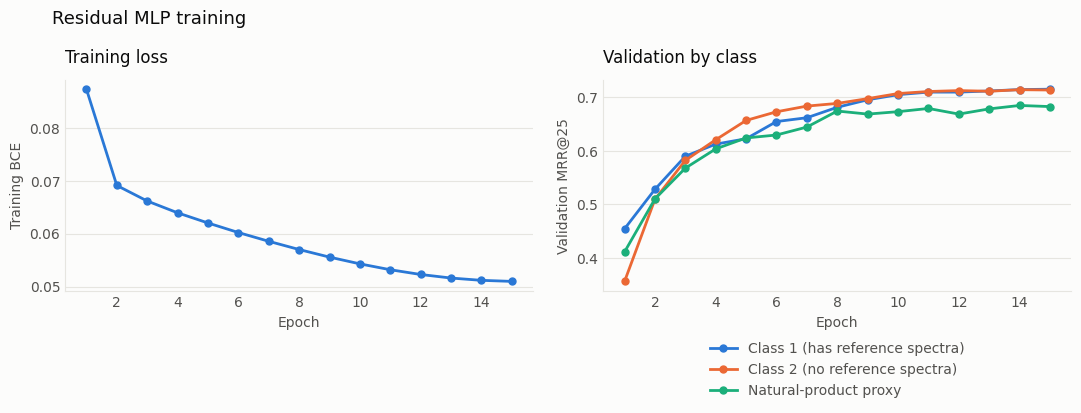

2026-11-23 05:45:37 | Saved figure /content/drive/MyDrive/CASMI/experiment_runs/residual_mlp_20261123_053259/figures/training_curves.png


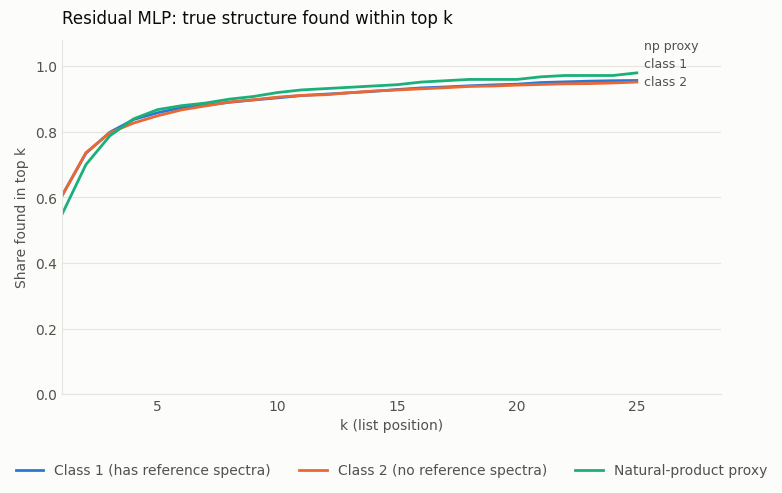

2026-11-23 05:45:37 | Saved figure /content/drive/MyDrive/CASMI/experiment_runs/residual_mlp_20261123_053259/figures/hit_curve.png


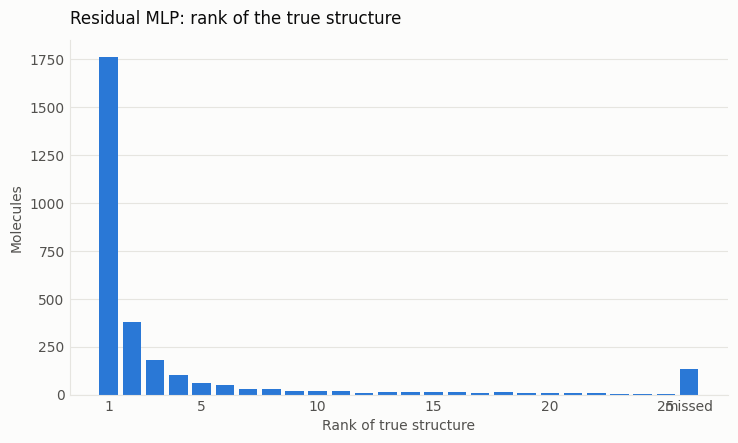

2026-11-23 05:45:38 | Saved figure /content/drive/MyDrive/CASMI/experiment_runs/residual_mlp_20261123_053259/figures/rank_histogram.png


In [9]:
if PLATFORM != "kaggle":
    probs = pipeline.predict_probs(
        model, v_mz, v_in, val.precursor_mz.to_numpy(), pipeline.adduct_ids(val.adduct), device
    )
    rankings = pipeline.rank_by_fingerprint(pool, pool_fp, val, probs, PPM)
    table = pipeline.evaluate(rankings, truth, keys, ci=True)
    run.table(table, "metrics")
    ranks = pipeline.rank_table(rankings, truth, keys)
    run.table(ranks, "per_molecule_ranks", index=False)
    run.table(pipeline.fingerprint_metrics(val, probs, truth, pool, pool_fp), "fingerprint_quality")
    run.figure(pipeline.plot_training(history, "Residual MLP training"), "training_curves")
    run.figure(pipeline.plot_hit_curve(ranks, "Residual MLP: true structure found within top k"), "hit_curve")
    run.figure(pipeline.plot_rank_histogram(ranks, "Residual MLP: rank of the true structure"), "rank_histogram")

### Submission
Predicts fingerprints for the test spectra, ranks mass-matched candidates by soft Tanimoto similarity and writes `submission.csv`. On Kaggle it loads the saved artifact instead of training. Outside Kaggle it also records the run in `experiment_log.csv` and saves a comparison across logged methods.

2026-11-23 05:45:39 | Experiment log updated: /content/drive/MyDrive/CASMI/experiment_runs/experiment_log.csv
2026-11-23 05:45:39 | Summary: {'date': '2026-11-23', 'version': 'Residual MLP', 'change': 'Residual MLP fingerprint predictor', 'val_MRR@25': 0.7141, 'class1': 0.7148, 'class2': 0.7133, 'np_proxy': 0.6824, 'LB': '', 'run_folder': 'residual_mlp_20261123_053259', 'runtime_minutes': 12.66}


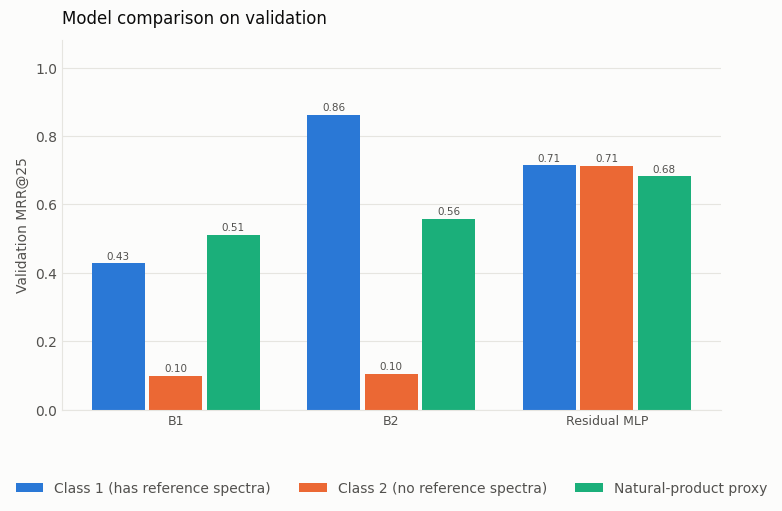

2026-11-23 05:45:39 | Saved figure /content/drive/MyDrive/CASMI/experiment_runs/residual_mlp_20261123_053259/figures/comparison.png
(400, 2)


In [10]:
if PLATFORM == "kaggle":
    hits = glob.glob("/kaggle/input/**/artifact.json", recursive=True)
    if not hits:
        raise FileNotFoundError("Attach the Kaggle Dataset holding this model's artifact folder.")
    model, pool_sub, fp_sub, info = pipeline.load_artifact(os.path.dirname(hits[0]), device)
    assert info["model_name"] == MODEL_NAME, info
else:
    pool_sub, fp_sub = pool, pool_fp
test, test_path = pipeline.load_test(DATA_DIR)
s_mz, s_in = pipeline.read_spectra(test_path, test.row_id.to_numpy(), MAX_PEAKS)
s_probs = pipeline.predict_probs(
    model, s_mz, s_in, test.precursor_mz.to_numpy(), pipeline.adduct_ids(test.adduct), device
)
final = pipeline.rank_by_fingerprint(pool_sub, fp_sub, test, s_probs, PPM)
sub = pipeline.write_submission(final, pool_sub, test, "submission.csv")
if PLATFORM != "kaggle":
    sub.to_csv(os.path.join(run.dir, "submission.csv"), index=False)
    log = run.finish(pipeline.log_line("Residual MLP", "Residual MLP fingerprint predictor", table))
    run.figure(pipeline.plot_comparison(log), "comparison")
print(sub.shape)

### Export in the team GitHub format
Writes everything the team repo expects into `github_export/` inside this run folder, laid out like the repo, and
zips it to `github_export.zip`. Unzip it at the repo root:

- `outputs/scores/<model_id>/val.parquet` and `test.parquet`: CandidateScores (`query_id`, `inchikey14`, `score`),
  checked with the same rules as `casmi.interfaces.write_scores`. `score` is the soft Tanimoto similarity for
  candidates inside the mass window; candidates added to fill the list to 25 get small negative scores, so sorting
  by score gives exactly the submission order. `outputs/` is gitignored: share these files on Drive, don't commit them.
- `experiments/entries/<date>_member3_<model_id>.yaml`: the experiment entry (fill in `lb_score` after submitting).
- `models/spectrum_encoders/<arch>/results/<run folder>/`: metrics, figures, logs and submission, without the
  model weights in `artifact/` (weights are gitignored; upload `artifact/` as a Kaggle Dataset instead).
- `models/spectrum_encoders/<arch>/results/RESULTS.md`: rows to paste into the model README tables.

Validation uses this notebook's own structure-level split (`casmi-split-v1`), not the team's frozen split.

In [11]:
MODEL_ID = "spectrum_encoders.arch1_residual_mlp"
CHANGE = "Residual MLP fingerprint predictor"


def candidate_scores(rankings, pool_, fp_packed, spectra, probs_, ppm=PPM):
    """CandidateScores rows (query_id, inchikey14, score) in the same order as the submission."""
    keys_ = pool_.key.to_numpy()
    pool_mass = pool_.mass.to_numpy()
    spectra = spectra.assign(pos=np.arange(len(spectra)))
    rows = []
    for mol, group in spectra.groupby("molecule_id", sort=False):
        ranked = list(rankings[mol][: pipeline.TOP_K])
        window = set(pipeline.window_indices(pool_mass, float(group.neutral_mass.median()), ppm).tolist())
        p = probs_[group.pos.to_numpy()].mean(axis=0)
        bits = np.unpackbits(fp_packed[ranked], axis=1).astype(np.float32)
        overlap = bits @ p
        tanimoto = overlap / (p.sum() + bits.sum(axis=1) - overlap + 1e-8)
        for rank, (i, t) in enumerate(zip(ranked, tanimoto, strict=True), start=1):
            rows.append((mol, keys_[i], float(t) if i in window else -rank / 1000.0))
    return pd.DataFrame(rows, columns=["query_id", "inchikey14", "score"])


def check_scores(df, n_queries):
    """Same rules as casmi.interfaces.validate_candidate_scores, plus top-25 and order checks."""
    assert list(df.columns) == ["query_id", "inchikey14", "score"], df.columns
    assert df.notna().all().all(), "nulls in CandidateScores"
    assert df.inchikey14.astype(str).str.fullmatch(r"[A-Z]{14}").all(), "invalid inchikey14"
    assert np.isfinite(df.score.to_numpy(dtype=float)).all(), "non-finite score"
    assert not df.duplicated(["query_id", "inchikey14"]).any(), "duplicate (query_id, inchikey14)"
    assert df.groupby("query_id").size().max() <= pipeline.TOP_K, "more than 25 candidates for a query"
    assert df.query_id.nunique() == n_queries, "missing queries"
    steps = df.groupby("query_id", sort=False).score.diff().dropna()
    assert (steps <= 1e-6).all(), "score order differs from the submission order"


if PLATFORM != "kaggle":
    import json
    import shutil

    if QUICK_RUN:
        print("QUICK_RUN is True: these files are only a pipeline check. Do not commit them.")
    export = os.path.join(run.dir, "github_export")
    arch = MODEL_ID.split(".")[1]
    run_name = os.path.basename(run.dir)
    results_dir = os.path.join(export, "models", "spectrum_encoders", arch, "results")

    # 1. CandidateScores for val and test
    scores_dir = os.path.join(export, "outputs", "scores", MODEL_ID)
    os.makedirs(scores_dir, exist_ok=True)
    val_scores = candidate_scores(rankings, pool, pool_fp, val, probs)
    check_scores(val_scores, val.molecule_id.nunique())
    test_scores = candidate_scores(final, pool_sub, fp_sub, test, s_probs)
    check_scores(test_scores, test.molecule_id.nunique())
    val_scores.to_parquet(os.path.join(scores_dir, "val.parquet"), index=False)
    test_scores.to_parquet(os.path.join(scores_dir, "test.parquet"), index=False)
    run.log(f"CandidateScores: val {val_scores.shape}, test {test_scores.shape}")

    # 2. Experiment entry (experiments/TEMPLATE.yaml fields)
    summary = json.load(open(os.path.join(run.dir, "summary.json")))
    gpu = json.load(open(os.path.join(run.dir, "environment.json"))).get("gpu") or str(device)
    per_class = {g: float(table.loc[g, "MRR@25"]) for g in table.index}
    entry_dir = os.path.join(export, "experiments", "entries")
    os.makedirs(entry_dir, exist_ok=True)
    entry_path = os.path.join(entry_dir, f"{summary['date']}_member3_{MODEL_ID}.yaml")
    with open(entry_path, "w") as handle:
        handle.write(
            "# Member 3 Colab run. Validation is Member 3's own split (casmi-split-v1), not the frozen split.\n"
            f"date: {summary['date']}\n"
            "member: 3\n"
            f"model_id: {MODEL_ID}\n"
            "version: v1\n"
            f'change: "{CHANGE}"\n'
            f"val_mrr: {per_class['balanced']:.4f}\n"
            "lb_score: null\n"
            "submitted: false\n"
            "notes: >-\n"
            f"  Own structure-level split (casmi-split-v1), {len(truth)} validation molecules.\n"
            f"  Per-class MRR@25: class 1 {per_class['class 1']:.4f}, class 2 {per_class['class 2']:.4f},\n"
            f"  np proxy {per_class['np proxy']:.4f}. Runtime {summary['runtime_minutes']} min on {gpu}.\n"
            f"  Run folder {run_name}. Set lb_score and submitted after the Kaggle submission.\n"
        )

    # 3. Run folder without model weights
    shutil.copytree(
        run.dir,
        os.path.join(results_dir, run_name),
        ignore=shutil.ignore_patterns("artifact", "github_export", "github_export.zip", "*.pt"),
    )

    # 4. README rows
    lines = [
        "| version | date | val MRR@25 | LB MRR@25 | notes |",
        "|---------|------|------------|-----------|-------|",
        f"| v1 | {summary['date']} | {per_class['balanced']:.4f} |  | own split casmi-split-v1, {run_name} |",
        "",
        "### Per-class val MRR@25",
        "| class | n | MRR@25 |",
        "|-------|---|--------|",
    ]
    lines += [f"| {g} | {int(table.loc[g, 'n'])} | {table.loc[g, 'MRR@25']:.4f} |" for g in table.index]
    with open(os.path.join(results_dir, "RESULTS.md"), "w") as handle:
        handle.write("\n".join(lines) + "\n")

    zip_path = shutil.make_archive(export, "zip", export)
    run.log(f"GitHub export ready: {zip_path}")
    for root, _, files in sorted(os.walk(export)):
        for name in sorted(files):
            print(os.path.relpath(os.path.join(root, name), export))

2026-11-23 05:45:40 | CandidateScores: val (72800, 3), test (10000, 3)
2026-11-23 05:45:41 | GitHub export ready: /content/drive/MyDrive/CASMI/experiment_runs/residual_mlp_20261123_053259/github_export.zip
experiments/entries/2026-11-23_member3_spectrum_encoders.arch1_residual_mlp.yaml
models/spectrum_encoders/arch1_residual_mlp/results/RESULTS.md
models/spectrum_encoders/arch1_residual_mlp/results/residual_mlp_20261123_053259/config.json
models/spectrum_encoders/arch1_residual_mlp/results/residual_mlp_20261123_053259/environment.json
models/spectrum_encoders/arch1_residual_mlp/results/residual_mlp_20261123_053259/fingerprint_quality.csv
models/spectrum_encoders/arch1_residual_mlp/results/residual_mlp_20261123_053259/metrics.csv
models/spectrum_encoders/arch1_residual_mlp/results/residual_mlp_20261123_053259/per_molecule_ranks.csv
models/spectrum_encoders/arch1_residual_mlp/results/residual_mlp_20261123_053259/run.log
models/spectrum_encoders/arch1_residual_mlp/results/residual_mlp_202